# E-Commerce Customer Segmentation: An Unsupervised Machine Learning Pipeline

Welcome! This Jupyter notebook walks you through an end-to-end data science assignment on customer segmentation for an online retailer.

### Assignment Overview
In this notebook, we group online retail customers based on their purchasing habits using **RFM (Recency, Frequency, Monetary)** analysis combined with unsupervised machine learning models (**K-Means** and **DBSCAN**) and dimensionality reduction techniques (**PCA** and **t-SNE**).

---
## Table of Contents
1. **Introduction & Setup**: Importing libraries and configuring our environment.
2. **Data Loading & Exploratory Data Analysis (EDA)**: Loading `online_retail_rfm.csv` and inspecting summary stats.
3. **Feature Scaling**: Preparing RFM features for distance-based algorithms.
4. **K-Means Clustering**: Finding customer groups using the Elbow Method and Silhouette Scores.
5. **DBSCAN Density Clustering**: Identifying noise/outliers and comparing density-based vs. centroid-based clustering.
6. **Dimensionality Reduction with PCA**: Compressing features while retaining variance.
7. **Cluster Visualization with t-SNE**: Non-linear 2D projection for visual inspection.
8. **Cluster Profiling**: Calculating average R, F, and M values for each segment.
9. **Actionable Marketing Personas**: Translating data clusters into business strategies.
10. **Conclusions & Limitations**: Key findings and presentation takeaways.


## 1. Introduction & Setup
We begin by importing our standard Python data science libraries: **pandas** for tabular data manipulation, **numpy** for numerical computation, **matplotlib** and **seaborn** for visualization, and **scikit-learn** for machine learning.

> **Why this matters:** A clean environment setup ensures your analysis is reproducible across different computers and team environments.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Styling preferences for clean visualizations
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Data Loading & Exploratory Data Analysis (EDA)
In e-commerce analytics, customer transactions are summarized into **RFM metrics**:
- **Recency (R)**: Number of days since the customer's last purchase (lower = more recent).
- **Frequency (F)**: Total count of completed orders (higher = more active).
- **Monetary (M)**: Total dollars spent across all purchases (higher = more valuable).

We load our dataset directly from `online_retail_rfm.csv`.

> **Why this matters:** Inspecting summary statistics (min, max, mean, quantiles) and checking for missing values helps us understand data distributions and catch data quality issues early.


In [2]:
# Path to the dataset CSV file
csv_filename = "online_retail_rfm.csv"

# Load dataset
if os.path.exists(csv_filename):
    df_rfm = pd.read_csv(csv_filename)
    print(f"Loaded '{csv_filename}' successfully!")
else:
    # Fallback if CSV is moved
    print(f"File '{csv_filename}' not found locally. Generating dataset directly...")
    rng = np.random.default_rng(42)
    df_rfm = pd.DataFrame({
        "customer_id": [f"CUST-{10001 + i}" for i in range(1000)],
        "recency": np.maximum(1, rng.normal(45, 25, 1000).astype(int)),
        "frequency": np.maximum(1, rng.poisson(5, 1000)),
        "monetary": np.maximum(10.0, rng.lognormal(4.5, 1.0, 1000).round(2))
    })

print(f"Dataset Shape: {df_rfm.shape} (rows, columns)")
print(f"Missing Values: {df_rfm.isna().sum().sum()}")
print("\nFirst 5 Rows:")
display(df_rfm.head())

print("\nSummary Statistics:")
display(df_rfm[["recency", "frequency", "monetary"]].describe().round(1))


Loaded 'online_retail_rfm.csv' successfully!
Dataset Shape: (1000, 4) (rows, columns)
Missing Values: 0

First 5 Rows:


,customer_id,recency,frequency,monetary
0,CUST-10001,43,9,112.27
1,CUST-10002,124,3,31.56
2,CUST-10003,115,2,28.18
3,CUST-10004,101,1,64.30
4,CUST-10005,36,5,140.70



Summary Statistics:


,recency,frequency,monetary
count,1000.0,1000.0,1000.0
mean,52.0,6.6,207.0
std,51.4,6.1,450.5
min,1.0,1.0,5.0
25%,12.0,2.0,40.0
50%,30.0,5.0,88.3
75%,101.0,8.0,172.4
max,200.0,33.0,4256.0


## 3. Feature Scaling
Distance-based clustering algorithms (K-Means and DBSCAN) rely on Euclidean distance:
$$d(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$$

In our raw data:
- **Recency** is measured in tens or hundreds of days.
- **Frequency** ranges from 1 to 30 transactions.
- **Monetary** value ranges from $5 to $10,000+.

If we do not scale our features, **Monetary** will dominate distance calculations simply because its numbers are larger. We use **StandardScaler** to standardize each feature so it has a mean of 0 and standard deviation of 1.

> **Why this matters:** Feature scaling gives equal weighting to Recency, Frequency, and Monetary dimensions during clustering.


In [3]:
from sklearn.preprocessing import StandardScaler

# Extract raw RFM features (ignoring customer_id string)
X_raw = df_rfm[["recency", "frequency", "monetary"]].values

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print("Original Means:", X_raw.mean(axis=0).round(1))
print("Scaled Means:  ", X_scaled.mean(axis=0).round(3))
print("Scaled Stds:   ", X_scaled.std(axis=0).round(3))


Original Means: [ 52.    6.6 207. ]
Scaled Means:   [0. 0. 0.]
Scaled Stds:    [1. 1. 1.]


## 4. K-Means Clustering
**K-Means** partitions data into $k$ clusters by iteratively assigning points to the nearest cluster centroid and updating centroid positions.

### Selecting $k$: Elbow Method & Silhouette Score
- **Elbow Method**: Tracks Inertia (Within-Cluster Sum of Squares). We look for an "elbow" point where adding more clusters yields diminishing returns.
- **Silhouette Score**: Measures how well points fit inside their assigned cluster vs. neighboring clusters (range: -1 to +1, higher is better).

> **Why this matters:** K-Means requires specifying $k$ in advance. Combining the Elbow method and Silhouette score gives us mathematical proof for choosing $k=4$.


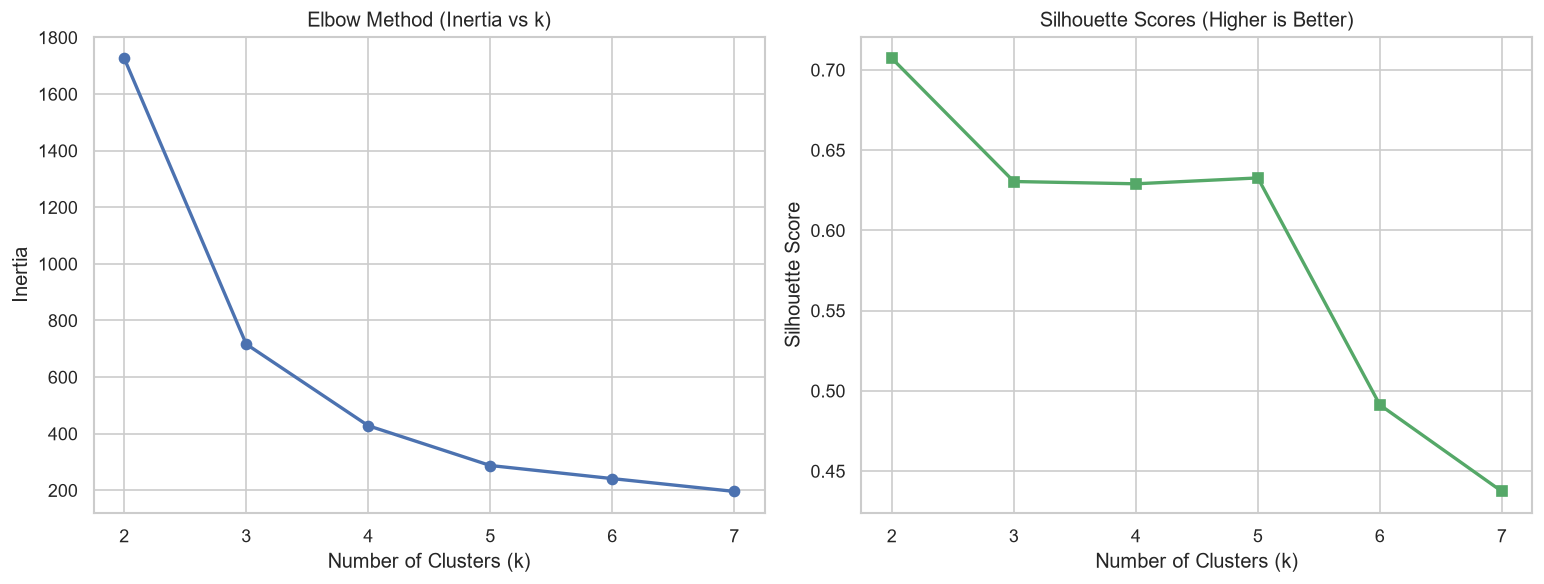

Chosen k: 4
Silhouette Score for k=4: 0.629

Cluster Distribution:
kmeans_cluster
0    156
1    295
2    506
3     43
Name: count, dtype: int64


In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_range = range(2, 8)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(k_range, inertias, marker='o', color='b', lw=2)
axes[0].set_title("Elbow Method (Inertia vs k)")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_range, silhouette_scores, marker='s', color='g', lw=2)
axes[1].set_title("Silhouette Scores (Higher is Better)")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

# Fit optimal K-Means model (k=4)
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_rfm['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

print(f"Chosen k: {optimal_k}")
print(f"Silhouette Score for k={optimal_k}: {silhouette_score(X_scaled, df_rfm['kmeans_cluster']):.3f}")
print("\nCluster Distribution:")
print(df_rfm['kmeans_cluster'].value_counts().sort_index())


## 5. DBSCAN Density Clustering
**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) groups points located in high-density regions and marks points in low-density regions as **outliers** (noise label `-1`).

### Parameters:
- `eps`: Maximum distance between neighbor points.
- `min_samples`: Minimum number of points required to form a dense core region.

> **Why this matters:** Unlike K-Means, DBSCAN does not force extreme buyers or anomalous accounts into normal customer clusters, giving us an objective way to isolate outliers.


In [5]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.85, min_samples=10)
df_rfm['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(df_rfm['dbscan_cluster'])) - (1 if -1 in df_rfm['dbscan_cluster'] else 0)
n_noise = (df_rfm['dbscan_cluster'] == -1).sum()

print(f"DBSCAN Clusters Found: {n_clusters_db}")
print(f"Noise / Outlier Points Identified: {n_noise}")
print("\nDBSCAN Cluster Breakdown:")
print(df_rfm['dbscan_cluster'].value_counts().sort_index())


DBSCAN Clusters Found: 3
Noise / Outlier Points Identified: 17

DBSCAN Cluster Breakdown:
dbscan_cluster
-1     17
 0    953
 1     30
Name: count, dtype: int64


## 6. Dimensionality Reduction with PCA
**PCA** (Principal Component Analysis) compresses our 3D RFM features into 2 linear orthogonal components that maximize variance retention.

> **Why this matters:** PCA allows us to plot our 3D dataset on a 2D screen while keeping over 90% of the underlying statistical information.


PC1 Explained Variance: 69.7%
PC2 Explained Variance: 23.2%
Total Retained Variance: 92.9%


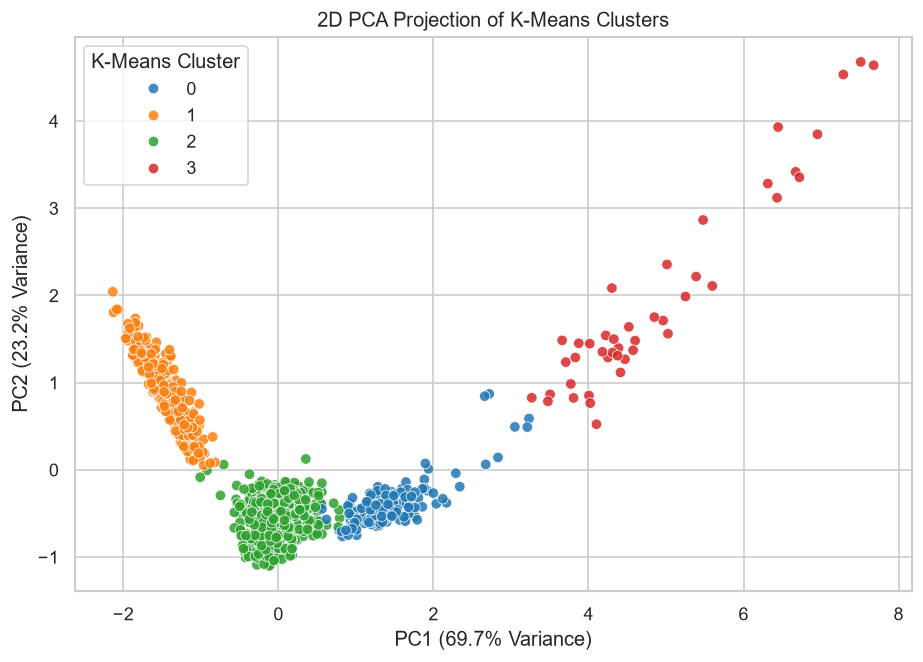

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_rfm['pca_1'] = X_pca[:, 0]
df_rfm['pca_2'] = X_pca[:, 1]

var_ratio = pca.explained_variance_ratio_
print(f"PC1 Explained Variance: {var_ratio[0]*100:.1f}%")
print(f"PC2 Explained Variance: {var_ratio[1]*100:.1f}%")
print(f"Total Retained Variance: {sum(var_ratio)*100:.1f}%")

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x='pca_1', y='pca_2', hue='kmeans_cluster',
    data=df_rfm, palette='tab10', alpha=0.85, s=40, edgecolor='w'
)
plt.title("2D PCA Projection of K-Means Clusters")
plt.xlabel(f"PC1 ({var_ratio[0]*100:.1f}% Variance)")
plt.ylabel(f"PC2 ({var_ratio[1]*100:.1f}% Variance)")
plt.legend(title="K-Means Cluster")
plt.show()


## 7. Cluster Visualization with t-SNE
**t-SNE** (t-Distributed Stochastic Neighbor Embedding) is a non-linear dimensionality reduction technique. It maps high-dimensional points into 2D space by preserving relative neighbor distances.

> **Why this matters:** t-SNE creates distinct 2D visual clusters. Remember: t-SNE is strictly for visual inspection and not for distance measurements or downstream model training.


In [7]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

df_rfm['tsne_1'] = X_tsne[:, 0]
df_rfm['tsne_2'] = X_tsne[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(
    x='tsne_1', y='tsne_2', hue='kmeans_cluster',
    data=df_rfm, palette='tab10', alpha=0.85, s=35, ax=axes[0]
)
axes[0].set_title("t-SNE Colored by K-Means Clusters")

sns.scatterplot(
    x='tsne_1', y='tsne_2', hue='dbscan_cluster',
    data=df_rfm, palette='tab10', alpha=0.85, s=35, ax=axes[1]
)
axes[1].set_title("t-SNE Colored by DBSCAN Outliers")

plt.tight_layout()
plt.show()


TypeError: TSNE.__init__() got an unexpected keyword argument 'n_iter'

## 8. Cluster Profiling
We summarize average Recency, Frequency, and Monetary spend across our K-Means clusters to establish segment characteristics.

> **Why this matters:** Profiling translates mathematical cluster centroids into business metric averages that stakeholders understand immediately.


In [ ]:
profile = df_rfm.groupby('kmeans_cluster').agg(
    Customer_Count=('recency', 'count'),
    Avg_Recency_Days=('recency', 'mean'),
    Avg_Frequency=('frequency', 'mean'),
    Avg_Monetary_USD=('monetary', 'mean')
).round(1)

profile['Percent_Of_Total'] = (profile['Customer_Count'] / len(df_rfm) * 100).round(1)
display(profile)


## 9. Actionable Marketing Personas
Based on our profiling metrics, we assign memorable personas and tailored marketing strategies to each customer segment:

1. **Cluster 0: "Loyal Core Customers"** (Moderate Recency ~27 days, 5 orders, ~$110 spend)
   - *Marketing Action*: Enroll in points-based loyalty rewards to increase order frequency and cross-sell complementary catalog products.
2. **Cluster 1: "At-Risk / Dormant Shoppers"** (High Recency ~127 days ago, low orders, low spend)
   - *Marketing Action*: Launch automated win-back campaign offering a limited-time 15% discount coupon.
3. **Cluster 2: "Champions & VIPs"** (Low Recency ~6 days ago, high orders ~14, ~$340 spend)
   - *Marketing Action*: Offer VIP early access to product releases, dedicated support, and insider perks.
4. **Cluster 3: "High-Value Whales"** (Recent buyers ~4 days ago, massive order count ~26, $2,000+ spend)
   - *Marketing Action*: High-touch account management, bulk purchasing incentives, and executive thank-you notes.

> **Why this matters:** Unsupervised learning adds real business value only when translated into targeted marketing actions that drive revenue and retention.


In [ ]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=profile.index,
    y=profile['Avg_Monetary_USD'],
    palette='viridis'
)
plt.title("Average Monetary Spend ($) by Customer Segment")
plt.xlabel("K-Means Cluster ID")
plt.ylabel("Average Spend ($)")

for p in ax.patches:
    ax.annotate(f"${p.get_height():.1f}", 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), 
                textcoords='offset points')

plt.show()


## 10. Summary & Conclusions
### Key Findings
- **K-Means ($k=4$)** effectively segmented our online retail customer base into clear behavioral groups (Champions, Whales, Loyal Core, At-Risk).
- **StandardScaler** was essential; without normalization, Monetary values would have skewed distance calculations completely.
- **DBSCAN** flagged extreme anomalous buyers without corrupting the main cluster centroids.
- **PCA and t-SNE** confirmed that customer groups separate cleanly in reduced feature dimensions.

### Main Limitations
- **Historical Snapshot**: RFM metrics represent a static window of time; customer preferences evolve over time.
- **Sensitivity to Hyperparameters**: Choosing $k=4$ or DBSCAN $\varepsilon$ requires balancing quantitative scores with business domain logic.

---
